# $L(2,\chi_{-3})\pm\tfrac23\zeta(2)$: new trajectories

Exact rational approximants, sampled up to index 500.
$\delta_N=-1-\log|\alpha-p_N/q_N|/\log q_N$ and
$D_N=-\log_{10}|\alpha-p_N/q_N|$, with reduced $p_N/q_N$.
Both constructions are new; no earlier result is known for either combination.

In [1]:
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 python-flint==0.9.0 matplotlib==3.11.2

## Setup

Both trajectories live in $G^{4,2}_{4,4}(1)$, which has rank 3 since the order drops at $z=1$.
We walk its $\theta$-companion form with exact rationals. Along the direction used here the span of
$e_0,e_1$ is invariant, so only the $2\times2$ block $F_N$ is kept, and $(s_0,s_1)$ is the first row
of $F_N^{-1}$, i.e. the first column of the dual walk.

In [2]:
import sys
import matplotlib.pyplot as plt
from flint import arb, ctx, fmpq, fmpq_mat, fmpq_poly, fmpz
from IPython.display import Markdown, display

sys.set_int_max_str_digits(0)
DEPTHS = list(range(10, 501, 10))
results, accuracy = {}, {}
_cache = {}


def cached(name, f):
    # Hurwitz zeta is slow at this precision: reuse a value computed at least as precisely.
    if _cache.get(name, (0, None))[0] < ctx.prec:
        _cache[name] = (ctx.prec, f())
    return _cache[name][1]


# L(2, chi_-3) = (zeta(2, 1/3) - zeta(2, 2/3))/9 and zeta(2, 1/3) + zeta(2, 2/3) = 8 zeta(2).
L = lambda: cached('L', lambda: (2 * arb(2).zeta(arb(1) / 3) - 8 * arb(2).zeta()) / 9)
target_minus = lambda: L() - 2 * arb(2).zeta() / 3
target_plus = lambda: L() + 2 * arb(2).zeta() / 3
I3 = fmpq_mat(3, 3, [1, 0, 0, 0, 1, 0, 0, 0, 1])


def theta(pos):
    # Companion matrix of theta on G^{4,2}_{4,4}(1) at pos = (a0, ..., a3; b0, ..., b3).
    A, B = fmpq_poly([1]), fmpq_poly([1])
    for a in pos[:4]:
        A *= fmpq_poly([1 - a, 1])
    for b in pos[4:]:
        B *= fmpq_poly([-b, 1])
    c = A - B
    if not c[3]:
        raise ZeroDivisionError("singular vertex")
    T = fmpq_mat(3, 3)
    for i in range(2):
        T[i + 1, i] = 1
    for i in range(3):
        T[i, 2] = -c[i] / c[3]
    return T


def step(pos, axis, sign):
    w = list(pos)
    if axis < 4:
        if sign > 0:
            old = w[axis]; w[axis] += 1; E = (theta(w) - old * I3).inv()
        else:
            E = theta(w) - (w[axis] - 1) * I3; w[axis] -= 1
    else:
        if sign > 0:
            E = theta(w) - w[axis] * I3; w[axis] += 1
        else:
            w[axis] -= 1; E = (theta(w) - w[axis] * I3).inv()
    return w, E


def primitive(M):
    Z, _ = M.numer_denom()
    g = fmpz(0)
    for row in Z.tolist():
        for x in row:
            g = g.gcd(x)
    return fmpq_mat(Z.nrows(), Z.ncols(), [fmpq(x // g) for row in Z.tolist() for x in row])


def period(start, direction, n):
    # One step of the trajectory from start + n*direction, by unit steps (b axes first), skipping singular ones.
    pos, rem, F = [s + n * v for s, v in zip(start, direction)], list(direction), I3
    while any(rem):
        moved = False
        for i in [4, 5, 6, 7, 0, 1, 2, 3]:
            if not rem[i]:
                continue
            sign = 1 if rem[i] > 0 else -1
            try:
                w, E = step(pos, i, sign)
                if not E.det():
                    continue
            except (ZeroDivisionError, ValueError):
                continue
            F, pos, rem[i], moved = primitive(F * E), w, rem[i] - sign, True
        if not moved:
            raise ZeroDivisionError("no regular unit-step route")
    return F


def dual_walk(start, direction, depths):
    # First row (s0, s1) of F_N^{-1}, for each N in depths.
    F, out = fmpq_mat(2, 2, [1, 0, 0, 1]), []
    for n in range(max(depths)):
        M = period(start, direction, n)
        assert M[2, 0] == 0 and M[2, 1] == 0
        F = primitive(F * fmpq_mat(2, 2, [M[0, 0], M[0, 1], M[1, 0], M[1, 1]]))
        if n + 1 in depths:
            Fi = F.inv()
            out.append((Fi[0, 0], Fi[0, 1]))
    return out


def measure_all(approximants, target):
    # The target is evaluated once, at twice the bit length of the largest denominator.
    pq = [(int(r.p), int(r.q)) for r in approximants]
    out = []
    with ctx.workprec(2 * max(q for _, q in pq).bit_length() + 256):
        alpha = target()
        for p, q in pq:
            error = abs(alpha - arb(p) / q)
            assert error > 0 and q > 1
            value = -1 - error.log() / arb(q).log()
            assert value.is_finite() and value.rad() < arb("1e-18")
            out.append((float(value.mid()), float((-error.log() / arb(10).log()).mid())))
    return out

## 1. New trajectory for $L(2,\chi_{-3})-\tfrac23\zeta(2)$

[New Directions in Irrationality](https://arxiv.org/abs/2610.27799).

**CMF:** $G^{4,2}_{4,4}(1)$ · **Start:** $(-1,0,2,\tfrac83;0,0,0,\tfrac23)$ · **Direction:** $(-10,-9,14,6;0,1,2,-2)$.
We use the **dual** walk. The extraction is
$$\frac{p_N}{q_N}=\frac{1410\,s_0-1571\,s_1}{-4500\,s_0+4950\,s_1}.$$

In [3]:
start = [fmpq(-1), fmpq(0), fmpq(2), fmpq(8, 3), fmpq(0), fmpq(0), fmpq(0), fmpq(2, 3)]
trajectory = [-10, -9, 14, 6, 0, 1, 2, -2]
walks = dual_walk(start, trajectory, DEPTHS)
approximants = [(1410 * s0 - 1571 * s1) / (-4500 * s0 + 4950 * s1) for s0, s1 in walks]

measurements = measure_all(approximants, target_minus)
deltas = [value[0] for value in measurements]
results[r'$L(2,\chi_{-3})-\frac{2}{3}\zeta(2)$'] = (DEPTHS, deltas)
accuracy[r'$L(2,\chi_{-3})-\frac{2}{3}\zeta(2)$'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.018715139388


## 2. New trajectory for $L(2,\chi_{-3})+\tfrac23\zeta(2)$

[New Directions in Irrationality](https://arxiv.org/abs/2610.27799).

**CMF:** $G^{4,2}_{4,4}(1)$ · **Start:** $(-1,0,2,\tfrac73;0,0,0,\tfrac13)$ · **Direction:** $(-10,-9,14,6;0,1,2,-2)$.
Same direction as above; only the start changes. We use the **dual** walk. The extraction is
$$\frac{p_N}{q_N}=\frac{-540\,s_0+677\,s_1}{-288\,s_0+360\,s_1}.$$

In [4]:
start = [fmpq(-1), fmpq(0), fmpq(2), fmpq(7, 3), fmpq(0), fmpq(0), fmpq(0), fmpq(1, 3)]
trajectory = [-10, -9, 14, 6, 0, 1, 2, -2]
walks = dual_walk(start, trajectory, DEPTHS)
approximants = [(-540 * s0 + 677 * s1) / (-288 * s0 + 360 * s1) for s0, s1 in walks]

measurements = measure_all(approximants, target_plus)
deltas = [value[0] for value in measurements]
results[r'$L(2,\chi_{-3})+\frac{2}{3}\zeta(2)$'] = (DEPTHS, deltas)
accuracy[r'$L(2,\chi_{-3})+\frac{2}{3}\zeta(2)$'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.019346073012


## Comparison

Only completed runs are shown. The two constructions approximate different constants.

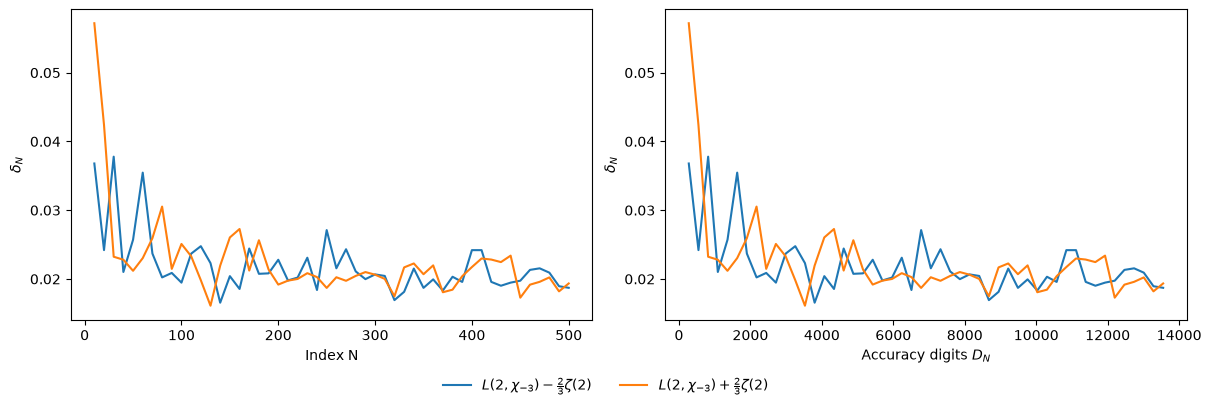

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, (depths, deltas) in results.items():
    axes[0].plot(depths, deltas, label=name)
    axes[1].plot(accuracy[name], deltas)
axes[0].set(xlabel="Index N", ylabel=r"$\delta_N$")
axes[1].set(xlabel=r"Accuracy digits $D_N$", ylabel=r"$\delta_N$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
plt.show()

## Overview

The measured column states the actual final index.

In [6]:
bounds = {
    r'$L(2,\chi_{-3})-\frac{2}{3}\zeta(2)$': '$\\delta\\approx0.019$',
    r'$L(2,\chi_{-3})+\frac{2}{3}\zeta(2)$': '$\\delta\\approx0.017$',
}
rows = ["| Construction | Published result | Measured delta |", "|:--|:--|:--|"]
for name, bound in bounds.items():
    if name in results:
        depths, deltas = results[name]
        value = f"{deltas[-1]:.12f} (N = {depths[-1]})"
    else:
        value = "Not computed"
    rows.append(f"| {name} | {bound} | {value} |")
display(Markdown("\n".join(rows)))

| Construction | Published result | Measured delta |
|:--|:--|:--|
| $L(2,\chi_{-3})-\frac{2}{3}\zeta(2)$ | $\delta\approx0.019$ | 0.018715139388 (N = 500) |
| $L(2,\chi_{-3})+\frac{2}{3}\zeta(2)$ | $\delta\approx0.017$ | 0.019346073012 (N = 500) |